# Modelos Matemáticos y Estadísticos Clásicos
## Diplomado en Data Science 2026

---

## Taller 2


**Integrantes**:

- Jaysson Leon
- Nadia Lell
- Matias Reyes
- Kelly Martinez



## Caso: Empresa de comercio electrónico

Formas parte del equipo de Data Science de una empresa de comercio electrónico. Un analista del equipo ha estado trabajando en distintos problemas relacionados con operación, tiempos de entrega, riesgo de atraso y planificación de demanda.

Tu tarea **no consiste solamente en ejecutar modelos**. Durante esta evaluación deberás revisar el trabajo del analista, decidir si sus conclusiones son correctas, proponer mejoras cuando corresponda y justificar tus decisiones.

### Objetivos evaluados

Se espera que seas capaz de:

- identificar qué herramienta estadística es apropiada para una pregunta;
- distinguir entre una asociación descriptiva, evidencia estadística y causalidad;
- interpretar correctamente resultados y métricas;
- detectar cuándo una conclusión **sí** está respaldada por los datos y cuándo **no**;
- comparar modelos y justificar cuál utilizarías.

### Importante

- El código de preparación de datos ya está entregado y **no forma parte de la evaluación**.
- Puedes agregar las celdas de código o texto que estimes necesarias.
- Toda conclusión debe estar respaldada por resultados reproducibles en el notebook.
- No se evaluará la cantidad de código, sino la calidad del análisis.

### Criterio de desarrollo

Este notebook mantiene la estructura del enunciado y desarrolla cada bloque con el enfoque trabajado en las clases del diplomado. La idea no es elegir un modelo solo porque entregue un número aparentemente mejor, sino distinguir entre descripción, evidencia estadística y causalidad, revisar supuestos, privilegiar modelos parsimoniosos y evaluar la capacidad predictiva con métricas coherentes con cada problema.

En las interpretaciones se usa un lenguaje aplicado: los resultados se explican en el contexto de pedidos, costo de despacho, atraso y demanda, evitando conclusiones más fuertes de lo que permiten los datos.


---

#  Preparación de datos

El siguiente código construye una tabla analítica a nivel de pedido a partir de cuatro tablas de origen.

**No es necesario modificar esta sección.**


In [1]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    RocCurveDisplay,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error
)

from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Los cuatro CSV deben estar en la misma carpeta del notebook.
# También se considera /mnt/data para que el notebook pueda ejecutarse en este entorno.
def buscar_archivo(nombre):
    candidatos = [
        Path(nombre),
        Path(".") / nombre,
        Path("/mnt/data") / nombre
    ]
    for ruta in candidatos:
        if ruta.exists():
            return ruta
    raise FileNotFoundError(
        f"No se encontró {nombre}. Deja los CSV en la misma carpeta que el notebook."
    )

RUTA_CUSTOMERS = buscar_archivo("customers - customers(1).csv")
RUTA_ORDER_ITEMS = buscar_archivo("order_items - order_items(1).csv")
RUTA_ORDERS = buscar_archivo("orders - orders(1).csv")
RUTA_PRODUCTS = buscar_archivo("products - products(1).csv")

customers = pd.read_csv(RUTA_CUSTOMERS)
order_items = pd.read_csv(RUTA_ORDER_ITEMS)
orders = pd.read_csv(RUTA_ORDERS)
products = pd.read_csv(RUTA_PRODUCTS)

print("customers:", customers.shape)
print("order_items:", order_items.shape)
print("orders:", orders.shape)
print("products:", products.shape)


customers: (15150, 5)
order_items: (16767, 7)
orders: (15000, 8)
products: (9208, 9)


In [2]:
for col in [
    "order_item_id",
    "price",
    "freight_value"
]:
    if col in order_items.columns:
        order_items[col] = pd.to_numeric(
            order_items[col],
            errors="coerce"
        )

for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(
            products[col],
            errors="coerce"
        )


# Fechas
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    if col in orders.columns:
        orders[col] = pd.to_datetime(
            orders[col],
            errors="coerce",
            format="mixed"
        )

# Variables geométricas de productos
for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(products[col], errors="coerce")

if all(c in products.columns for c in ["product_length_cm", "product_height_cm", "product_width_cm"]):
    products["product_volume_cm3"] = (
        products["product_length_cm"]
        * products["product_height_cm"]
        * products["product_width_cm"]
    )

# Enriquecer ítems con atributos de producto
items_prod = order_items.merge(
    products[
        [c for c in [
            "product_id",
            "product_category_name",
            "product_weight_g",
            "product_volume_cm3"
        ] if c in products.columns]
    ],
    on="product_id",
    how="left"
)

# Agregación a nivel de pedido
agg_dict = {
    "n_items": ("order_item_id", "count"),
    "total_price": ("price", "sum"),
    "total_freight": ("freight_value", "sum"),
    "avg_item_price": ("price", "mean"),
    "n_products": ("product_id", "nunique"),
}

if "product_category_name" in items_prod.columns:
    agg_dict["n_categories"] = ("product_category_name", "nunique")
if "product_weight_g" in items_prod.columns:
    agg_dict["total_weight_g"] = ("product_weight_g", "sum")
if "product_volume_cm3" in items_prod.columns:
    agg_dict["total_volume_cm3"] = ("product_volume_cm3", "sum")

order_agg = (
    items_prod
    .groupby("order_id")
    .agg(**agg_dict)
    .reset_index()
)

# Tabla analítica
df = (
    orders
    .merge(customers, on="customer_id", how="left")
    .merge(order_agg, on="order_id", how="left")
)

# Variables derivadas
df["purchase_date"] = df["order_purchase_timestamp"].dt.floor("D")
df["purchase_weekday"] = df["order_purchase_timestamp"].dt.day_name()
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["is_weekend_purchase"] = df["order_purchase_timestamp"].dt.dayofweek.ge(5).astype(int)

df["delivery_days"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df["delay_days"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

df["days_to_carrier"] = (
    df["order_delivered_carrier_date"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400


df["remaining_days"] = (
    df["order_estimated_delivery_date"]
    - df["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

df["approval_hours"] = (
    df["order_approved_at"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 3600


df["late_delivery"] = np.where(
    df["order_delivered_customer_date"].notna()
    & df["order_estimated_delivery_date"].notna(),
    (df["delay_days"] > 0).astype(int),
    np.nan
)

df["freight_ratio"] = df["total_freight"] / df["total_price"].replace(0, np.nan)

# Solo pedidos entregados para análisis de tiempos
delivered = df[
    (df["order_status"] == "delivered")
    & df["delivery_days"].notna()
].copy()

print("Tabla analítica:", df.shape)
print("Pedidos entregados:", delivered.shape)

display(delivered.head())


Tabla analítica: (15150, 31)
Pedidos entregados: (14688, 31)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,n_items,total_price,total_freight,avg_item_price,n_products,n_categories,total_weight_g,total_volume_cm3,purchase_date,purchase_weekday,purchase_month,is_weekend_purchase,delivery_days,delay_days,days_to_carrier,remaining_days,approval_hours,late_delivery,freight_ratio
0,3b14820d642ea72e95df3289b6539c1c,4248fddd68e3375c24e743290ce2d9fa,delivered,2018-04-02 13:01:06,2018-04-02 13:10:21,2018-04-04 23:42:34,2018-04-12 17:12:13,2018-04-23,a79c62e50e66e1036ba2cb2e5e00aff3,37190,tres pontas,MG,1.000,75.900,19.500,75.900,1.000,1.000,700.000,"6,912.000",2018-04-02,Monday,2018-04,0,10.174,-10.283,2.445,18.012,0.154,0.000,0.257
1,8a795486f112df15565463862960aa40,e093120ffd5c259e2decb4ff5266f0dd,delivered,2018-05-20 20:28:32,2018-05-22 09:36:09,2018-05-22 15:48:00,2018-06-01 11:50:31,2018-05-29,81ec41f3b0c51a9df15c5957140686fa,13084,campinas,SP,1.000,95.900,11.300,95.900,1.000,1.000,"1,400.000","27,000.000",2018-05-20,Sunday,2018-05,1,11.640,3.493,1.805,6.342,37.127,1.000,0.118
2,7aa2471c1e8d0cd89eec9459fde59414,0eb400f3e6d2f08e70d2ab5af9c203f4,delivered,2017-09-18 19:09:52,2017-09-20 02:10:42,2017-09-21 19:37:10,2017-09-27 19:09:10,2017-10-04,c64b0bf5855e1d6ba223d649298c2915,36889,muriae,MG,1.000,81.000,42.710,81.000,1.000,1.000,"18,100.000","4,332.000",2017-09-18,Monday,2017-09,0,9.000,-6.202,3.019,12.183,31.014,0.000,0.527
3,95cf53396116b5dd518b5ba1c11a0bb5,3b2e666d92ce663a2f35ba3a6bb5df6a,delivered,2017-04-21 19:31:13,2017-04-21 19:45:10,2017-04-25 13:08:20,2017-05-04 16:46:54,2017-05-19,4113a7e912e87f632986e0562da140c7,74075,goiania,GO,1.000,59.000,17.840,59.000,1.000,1.000,275.000,"1,936.000",2017-04-21,Friday,2017-04,0,12.886,-14.301,3.734,23.453,0.233,0.000,0.302
4,6c5eb0920626d3ff5588d03d6f2d4936,1b83beaaa59c8cdfe738f7ead2517da8,delivered,2018-03-15 15:22:28,2018-03-17 03:08:57,2018-03-19 21:14:58,2018-05-03 11:29:52,2018-04-30,d69a93bce76b26886f72125e60b01cec,69040,manaus,AM,1.000,69.900,57.040,69.900,1.000,1.000,"1,200.000","21,000.000",2018-03-15,Thursday,2018-03,0,48.838,3.479,4.245,41.115,35.775,1.000,0.816


### Diccionario resumido de la tabla analítica

| Variable | Descripción |
|---|---|
| `order_id` | Identificador del pedido |
| `customer_state` | Estado/región del cliente |
| `purchase_date` | Fecha de compra |
| `purchase_weekday` | Día de la semana de compra |
| `is_weekend_purchase` | 1 si la compra se realizó sábado o domingo |
| `n_items` | Número de ítems del pedido |
| `n_products` | Número de productos distintos |
| `n_categories` | Número de categorías distintas, si está disponible |
| `total_price` | Valor total de los productos |
| `total_freight` | Valor total del despacho |
| `avg_item_price` | Precio promedio de los ítems |
| `total_weight_g` | Peso total aproximado de los productos |
| `total_volume_cm3` | Volumen total aproximado |
| `delivery_days` | Días transcurridos desde compra hasta entrega |
| `delay_days` | Días de diferencia respecto de la fecha comprometida |
| `days_to_carrier` | Número de días transcurridos desde que se realiza la compra hasta que el pedido es entregado al transportista. |
| `remaining_days` | Número de días disponibles entre la entrega del pedido al transportista y la fecha estimada de entrega al cliente. |
| `approval_hours` | Número de horas transcurridas desde que se realiza la compra hasta que el pedido es aprobado. |
| `late_delivery` | 1 si el pedido llegó después de la fecha comprometida |
| `freight_ratio` | Costo de despacho dividido por valor de productos |

---




## Primer bloque (20 puntos)

El analista preparó la siguiente tabla cruzada entre **tamaño del pedido** y **atraso**.

Primero creó dos grupos:

- `1_item`: pedidos con un solo ítem;
- `2_o_mas`: pedidos con dos o más ítems.

In [3]:
analisis_1 = delivered[
    delivered["late_delivery"].notna()
    & delivered["n_items"].notna()
].copy()

analisis_1["grupo_items"] = np.where(
    analisis_1["n_items"] == 1,
    "1_item",
    "2_o_mas"
)

tabla = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"]
)

tabla


late_delivery,0.000,1.000
grupo_items,,
1_item,12054,1080
2_o_mas,1309,96


El analista luego calculó dos tablas:



In [4]:
# Tabla A
tabla_fila = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="index"
)

tabla_fila


late_delivery,0.000,1.000
grupo_items,,
1_item,0.918,0.082
2_o_mas,0.932,0.068


In [5]:
# Tabla B
tabla_columna = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="columns"
)

tabla_columna


late_delivery,0.000,1.000
grupo_items,,
1_item,0.902,0.918
2_o_mas,0.098,0.082



El analista afirma:

> "El analista observa que en la Tabla B el valor asociado a 1_item y late_delivery=1 es 0,918 y concluye que “los pedidos de un ítem tienen 91,8% de probabilidad de atraso”. ¿Es correcta esta interpretación?"


1. Explique qué representa el valor 0,082 de la Tabla A.  

2. Explique qué representa el valor 0,918 de la Tabla B.

3. ¿Cuál de las dos tablas permite comparar la probabilidad de atraso entre
pedidos de 1 ítem y de 2 o más ítems?

4. ¿Los resultados descriptivos apoyan la hipótesis del analista?

5. Evalúe si la diferencia observada es solo una cuestión de la muestra. Considere y explicite los supuestos/límites necesarios.

6. ¿Puede concluir que cambiar el número de ítems de un pedido modifica causalmente su probabilidad de atraso? Explique.

### Tu análisis


In [6]:
# 1) Comparación descriptiva de las probabilidades de atraso
riesgo_atraso = tabla_fila[1.0].rename("prob_atraso")
resumen_riesgo = pd.DataFrame({
    "prob_atraso": riesgo_atraso,
    "porcentaje_atraso": riesgo_atraso * 100
})

display(resumen_riesgo)

diferencia_pp = (
    tabla_fila.loc["1_item", 1.0]
    - tabla_fila.loc["2_o_mas", 1.0]
) * 100

riesgo_relativo = (
    tabla_fila.loc["1_item", 1.0]
    / tabla_fila.loc["2_o_mas", 1.0]
)

print(f"Diferencia descriptiva: {diferencia_pp:.2f} puntos porcentuales")
print(f"Razón de riesgos descriptiva: {riesgo_relativo:.3f}")

# 2) Prueba chi-cuadrado de independencia
chi2, p_value, grados_libertad, esperadas = chi2_contingency(tabla)

print(f"\nChi-cuadrado: {chi2:.3f}")
print(f"p-value: {p_value:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Frecuencia esperada mínima: {esperadas.min():.2f}")

,prob_atraso,porcentaje_atraso
grupo_items,,
1_item,0.082,8.223
2_o_mas,0.068,6.833


Diferencia descriptiva: 1.39 puntos porcentuales
Razón de riesgos descriptiva: 1.203

Chi-cuadrado: 3.115
p-value: 0.0776
Grados de libertad: 1
Frecuencia esperada mínima: 113.64


**Respuesta e interpretación**

**1. ¿Qué representa el 0,082 de la Tabla A?**  
La clave acá es fijarse en cuál es el denominador. Como la Tabla A está normalizada por filas, cada fila suma 1. Por eso el 0,082 se interpreta dentro del grupo `1_item`: de todos los pedidos que tenían un solo ítem, aproximadamente el **8,22% llegó atrasado**. En notación de probabilidad, esto es \(P(\text{atraso}\mid\text{1 ítem})\).

**2. ¿Qué representa el 0,918 de la Tabla B?**  
En la Tabla B la normalización es por columnas, así que ahora el denominador son todos los pedidos que comparten el mismo estado de atraso. El 0,918 significa que, **entre todos los pedidos que se atrasaron, cerca del 91,8% tenía un solo ítem**. Esto corresponde a \(P(\text{1 ítem}\mid\text{atraso})\), que no es lo mismo que \(P(\text{atraso}\mid\text{1 ítem})\). Por eso la interpretación original del analista está invertida.

**3. ¿Qué tabla sirve para comparar la probabilidad de atraso?**  
La Tabla A, porque la pregunta que queremos responder es qué proporción se atrasa **dentro de cada grupo de tamaño de pedido**. Ahí podemos comparar directamente el 8,22% de `1_item` con la tasa de `2_o_mas`.

**4. ¿Los resultados descriptivos apoyan la idea de que un grupo se atrasa más?**  
En esta muestra sí aparece una diferencia: los pedidos de un ítem tienen una tasa de atraso de **8,22%** y los de dos o más ítems de **6,83%**. La diferencia es de aproximadamente **1,39 puntos porcentuales**. También se puede expresar con una razón de riesgos descriptiva de 1,20, es decir, en la muestra el riesgo observado es cerca de 20% mayor en el grupo de un ítem. Esto describe lo que vemos en estos datos, pero todavía no nos dice si la diferencia es suficientemente clara como para generalizarla.

**5. ¿La diferencia puede deberse solo a la muestra?**  
Para pasar de la descripción a una conclusión estadística usamos una prueba \(\chi^2\) de independencia. La hipótesis nula plantea que el tamaño del pedido y el atraso son independientes. El resultado fue \(\chi^2=3,115\) con **p-value = 0,0776**. Como el p-value es mayor que 0,05, no tenemos evidencia suficiente para rechazar la independencia al nivel de significancia de 5%. En otras palabras, vemos una diferencia descriptiva, pero con esta muestra no alcanza para afirmar estadísticamente que las tasas de atraso sean distintas. Las frecuencias esperadas son mayores que 5, por lo que ese requisito del test se cumple. Además, estamos suponiendo que cada pedido puede tratarse como una observación independiente.

**6. ¿Podemos hablar de causalidad?**  
No. Aunque la diferencia hubiese sido significativa, seguiríamos hablando de una asociación observada. Los datos son observacionales y pueden existir otros factores relacionados con el atraso, como distancia, transportista, tipo de producto o condiciones logísticas. Por lo tanto, con este análisis no podemos concluir que cambiar el número de ítems provoque por sí solo un cambio en la probabilidad de atraso.


---

# Segundo Bloque (30 puntos)

El equipo está tratando de entender qué determina el costo de despacho de un pedido.

El analista propone dos modelos.

### Modelo A

Utiliza solamente una variable:


In [7]:
freight_data = delivered[
    delivered["total_freight"].notna()
    & delivered["total_weight_g"].notna()
    & delivered["total_volume_cm3"].notna()
    & delivered["total_price"].notna()
].copy()

modelo_A = smf.ols(
    "total_freight ~ total_volume_cm3",
    data=freight_data
).fit()

print(modelo_A.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.410
Method:                 Least Squares   F-statistic:                 1.008e+04
Date:                Sun, 30 Aug 2026   Prob (F-statistic):               0.00
Time:                        19:49:12   Log-Likelihood:                -60952.
No. Observations:               14539   AIC:                         1.219e+05
Df Residuals:                   14537   BIC:                         1.219e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           15.0518      0.154  

### Modelo B

Se consideró agregar 3 más!

In [8]:
modelo_B = smf.ols(
    """
    total_freight
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    """,
    data=freight_data
).fit()

print(modelo_B.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.581
Model:                            OLS   Adj. R-squared:                  0.581
Method:                 Least Squares   F-statistic:                     5033.
Date:                Sun, 30 Aug 2026   Prob (F-statistic):               0.00
Time:                        19:49:12   Log-Likelihood:                -58463.
No. Observations:               14539   AIC:                         1.169e+05
Df Residuals:                   14534   BIC:                         1.170e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.6562      0.271  

El analista concluye:

> “El Modelo B es necesariamente mejor porque tiene más variables y un R² mayor.”

Tu tarea es **evaluar críticamente su trabajo**.

Debes:

1. explicar si estás de acuerdo o no con la afirmación;
2. comparar los modelos utilizando criterios estadísticos que consideres pertinentes;
3. interpretar al menos **dos coeficientes** del Modelo B;
4. revisar gráficamente los supuestos/diagnósticos que consideres relevantes;
5. proponer y ajustar un **Modelo C** que consideres mejor especificado. Puedes incorporar variables disponibles en `freight_data`, transformar variables o eliminar variables;
6. recomendar finalmente A, B o C y justificar tu elección.

### Tu análisis


,Modelo,R2,R2_ajustado,AIC,BIC
0,A,0.410,0.410,"121,907.293","121,922.462"
1,B,0.581,0.581,"116,935.270","116,973.193"


Comparación de modelos anidados A vs B:


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,"14,537.000","3,727,636.464",0.000,NaN,NaN,NaN
1,"14,534.000","2,646,884.690",3.000,"1,080,751.774","1,978.130",0.000



Coeficientes del Modelo B:


,coeficiente,p_value
Intercept,0.656,0.015
total_price,0.021,0.000
total_weight_g,0.002,0.000
total_volume_cm3,0.000,0.000
n_items,11.710,0.000



VIF Modelo B:


,Variable,VIF
0,Intercept,5.845
1,total_price,1.133
2,total_weight_g,3.337
3,total_volume_cm3,3.355
4,n_items,1.096


,Diagnóstico,Valor
0,Breusch-Pagan p-value,0.000
1,Jarque-Bera p-value,0.000
2,Durbin-Watson,1.991


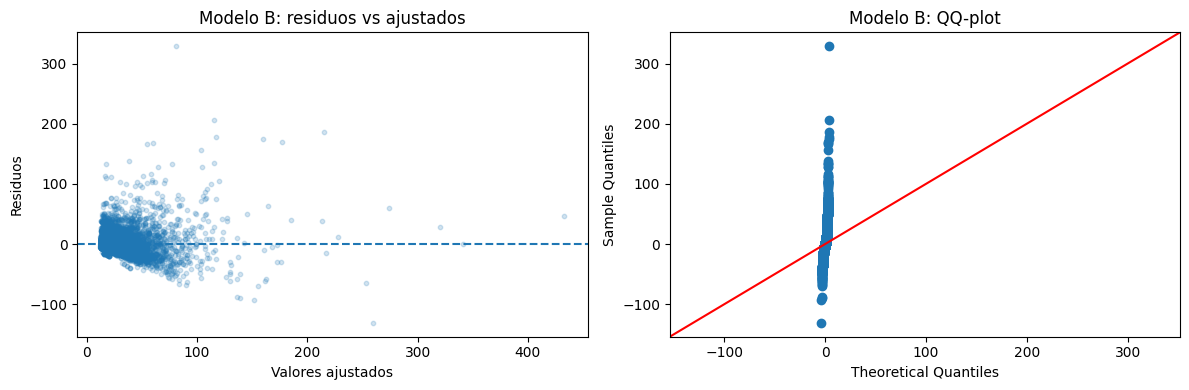

                              OLS Regression Results                              
Dep. Variable:     np.sqrt(total_freight)   R-squared:                       0.543
Model:                                OLS   Adj. R-squared:                  0.543
Method:                     Least Squares   F-statistic:                     2874.
Date:                    Sun, 30 Aug 2026   Prob (F-statistic):               0.00
Time:                            19:49:13   Log-Likelihood:                -21157.
No. Observations:                   14539   AIC:                         4.233e+04
Df Residuals:                       14532   BIC:                         4.238e+04
Df Model:                               6                                         
Covariance Type:                nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

,Diagnóstico,Valor
0,Breusch-Pagan p-value,0.000
1,Jarque-Bera p-value,0.000
2,Durbin-Watson,1.993
3,Asimetría residuos,1.083
4,Curtosis residuos,9.846


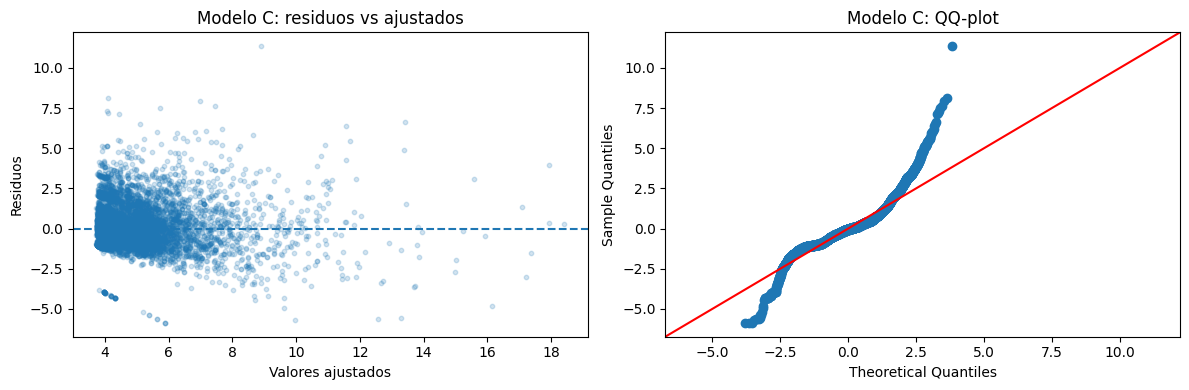


Comparación predictiva fuera de muestra:


,Modelo,MAE,RMSE
0,A,9.095,15.543
1,B,7.420,12.994
2,C,7.051,12.977


In [9]:
# Comparación estadística de los modelos A y B
comparacion_AB = pd.DataFrame({
    "Modelo": ["A", "B"],
    "R2": [modelo_A.rsquared, modelo_B.rsquared],
    "R2_ajustado": [modelo_A.rsquared_adj, modelo_B.rsquared_adj],
    "AIC": [modelo_A.aic, modelo_B.aic],
    "BIC": [modelo_A.bic, modelo_B.bic]
})

display(comparacion_AB)

print("Comparación de modelos anidados A vs B:")
display(anova_lm(modelo_A, modelo_B))

print("\nCoeficientes del Modelo B:")
display(pd.DataFrame({
    "coeficiente": modelo_B.params,
    "p_value": modelo_B.pvalues
}))

# Diagnóstico de multicolinealidad
X_B = pd.DataFrame(
    modelo_B.model.exog,
    columns=modelo_B.model.exog_names
)

vif_B = pd.DataFrame({
    "Variable": X_B.columns,
    "VIF": [
        variance_inflation_factor(X_B.values, i)
        for i in range(X_B.shape[1])
    ]
})

print("\nVIF Modelo B:")
display(vif_B)

# Diagnósticos numéricos de residuos
bp_B = het_breuschpagan(modelo_B.resid, modelo_B.model.exog)
jb_B = jarque_bera(modelo_B.resid)
dw_B = durbin_watson(modelo_B.resid)

diagnosticos_B = pd.DataFrame({
    "Diagnóstico": [
        "Breusch-Pagan p-value",
        "Jarque-Bera p-value",
        "Durbin-Watson"
    ],
    "Valor": [bp_B[1], jb_B[1], dw_B]
})

display(diagnosticos_B)

# Diagnósticos gráficos del Modelo B
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(modelo_B.fittedvalues, modelo_B.resid, alpha=0.20, s=10)
ax[0].axhline(0, linestyle="--")
ax[0].set_xlabel("Valores ajustados")
ax[0].set_ylabel("Residuos")
ax[0].set_title("Modelo B: residuos vs ajustados")

sm.qqplot(modelo_B.resid, line="45", ax=ax[1])
ax[1].set_title("Modelo B: QQ-plot")

plt.tight_layout()
plt.show()

# Modelo C
# Se transforma la respuesta con raíz cuadrada para reducir asimetría y se agregan
# dos interacciones que permiten que el efecto de peso y volumen varíe con n_items.
modelo_C = smf.ols(
    """
    np.sqrt(total_freight)
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    + total_weight_g:n_items
    + total_volume_cm3:n_items
    """,
    data=freight_data
).fit()

print(modelo_C.summary())

bp_C = het_breuschpagan(modelo_C.resid, modelo_C.model.exog)
jb_C = jarque_bera(modelo_C.resid)
dw_C = durbin_watson(modelo_C.resid)

diagnosticos_C = pd.DataFrame({
    "Diagnóstico": [
        "Breusch-Pagan p-value",
        "Jarque-Bera p-value",
        "Durbin-Watson",
        "Asimetría residuos",
        "Curtosis residuos"
    ],
    "Valor": [bp_C[1], jb_C[1], dw_C, jb_C[2], jb_C[3]]
})

print("\nDiagnósticos Modelo C:")
display(diagnosticos_C)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(modelo_C.fittedvalues, modelo_C.resid, alpha=0.20, s=10)
ax[0].axhline(0, linestyle="--")
ax[0].set_xlabel("Valores ajustados")
ax[0].set_ylabel("Residuos")
ax[0].set_title("Modelo C: residuos vs ajustados")

sm.qqplot(modelo_C.resid, line="45", ax=ax[1])
ax[1].set_title("Modelo C: QQ-plot")

plt.tight_layout()
plt.show()

# Comparación predictiva en una muestra no usada para ajustar
freight_train, freight_test = train_test_split(
    freight_data,
    test_size=0.20,
    random_state=42
)

modelo_A_train = smf.ols(
    "total_freight ~ total_volume_cm3",
    data=freight_train
).fit()

modelo_B_train = smf.ols(
    """
    total_freight
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    """,
    data=freight_train
).fit()

modelo_C_train = smf.ols(
    """
    np.sqrt(total_freight)
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    + total_weight_g:n_items
    + total_volume_cm3:n_items
    """,
    data=freight_train
).fit()

pred_A = modelo_A_train.predict(freight_test)
pred_B = modelo_B_train.predict(freight_test)

# Para volver a la escala original del costo se eleva al cuadrado la predicción de C.
pred_C = np.maximum(modelo_C_train.predict(freight_test), 0) ** 2

comparacion_pred = pd.DataFrame({
    "Modelo": ["A", "B", "C"],
    "MAE": [
        mean_absolute_error(freight_test["total_freight"], pred_A),
        mean_absolute_error(freight_test["total_freight"], pred_B),
        mean_absolute_error(freight_test["total_freight"], pred_C)
    ],
    "RMSE": [
        root_mean_squared_error(freight_test["total_freight"], pred_A),
        root_mean_squared_error(freight_test["total_freight"], pred_B),
        root_mean_squared_error(freight_test["total_freight"], pred_C)
    ]
})

print("\nComparación predictiva fuera de muestra:")
display(comparacion_pred)


**Recomendación final**

**1 y 2. Comparación entre A y B.**  
No estoy de acuerdo con la frase de que B sea mejor *porque tiene más variables*. En una regresión múltiple el \(R^2\) normalmente aumenta cuando agregamos predictores, incluso si el aporte real de alguno es pequeño. Por eso lo correcto es mirar el conjunto: \(R^2\) ajustado, AIC, BIC, significancia de los coeficientes, residuos y, si también nos interesa predecir, el error en datos que no se usaron para ajustar el modelo.

En este caso, después de hacer esa comparación, **B sí resulta claramente mejor que A**, pero por razones estadísticas y no por la cantidad de variables. El \(R^2\) ajustado sube de aproximadamente **0,410 a 0,581**, AIC y BIC bajan de manera importante y la comparación de modelos anidados muestra que las variables agregadas aportan información en conjunto.

**3. Interpretación de coeficientes.**  
El coeficiente de `total_weight_g` es aproximadamente 0,00156. Como está medido por gramo, es más fácil interpretarlo por kilogramo: manteniendo constantes precio, volumen y número de ítems, **1.000 gramos adicionales se asocian con un aumento promedio cercano a 1,56 unidades monetarias en el costo de despacho**. Por otro lado, el coeficiente de `n_items` es aproximadamente 11,71, por lo que, para pedidos con el mismo precio, peso y volumen, agregar un ítem se asocia con un aumento promedio de unas **11,71 unidades monetarias** en `total_freight`. Son asociaciones condicionales al resto del modelo y no efectos causales.

**4. Diagnósticos del Modelo B.**  
Los VIF de peso y volumen están alrededor de 3,3. Esto indica una colinealidad moderada, pero no una situación severa que obligue a eliminar una de las variables. Por eso no quitaría `total_volume_cm3` solamente por ese criterio. El problema más evidente aparece en los residuos: Breusch-Pagan rechaza homocedasticidad y el QQ-plot junto con Jarque-Bera muestran colas y observaciones extremas que se alejan de la normalidad. Durbin-Watson está cerca de 2, así que no se observa una señal importante de autocorrelación en el orden de las observaciones.

**5. Propuesta de Modelo C.**  
Para C probé una transformación de raíz cuadrada sobre el costo de despacho, porque `total_freight` es una variable positiva y bastante asimétrica. También incorporé interacciones entre `n_items` con peso y volumen para permitir que el efecto de esas variables cambie según el tamaño del pedido. Los residuos mejoran en asimetría y curtosis, aunque la heterocedasticidad no desaparece completamente. Por eso lo veo como una mejora, no como un modelo perfecto.

Además quise revisar que la mejora no fuera solo dentro de la misma muestra. Reservando 20% de los pedidos como test, A obtiene aproximadamente **MAE 9,10 y RMSE 15,54**, B mejora a **MAE 7,42 y RMSE 12,99**, y C llega a **MAE 7,05 y RMSE 12,98**. Me quedaría con **C** entre estas tres alternativas porque mantiene una interpretación razonable y consigue el menor MAE fuera de muestra. De todas formas, la heterocedasticidad que sigue apareciendo indica que todavía hay estructura que el modelo lineal no está capturando bien, por lo que en un trabajo posterior revisaría errores robustos, ponderaciones u otra familia de modelos.


---

# Tercer Bloque (30 puntos)

El objetivo ahora es distinto:

> Al momento de procesar un pedido, queremos estimar el riesgo de que llegue después de la fecha comprometida.

El analista ajustó inicialmente el siguiente modelo:


In [10]:
logit_data = delivered[
    delivered["late_delivery"].notna()
    & delivered["total_price"].notna()
    & delivered["total_freight"].notna()
    & delivered["n_items"].notna()
    & delivered["n_categories"].notna()
    & delivered["days_to_carrier"].notna()
    & delivered["remaining_days"].notna()
    & delivered["approval_hours"].notna()
].copy()

modelo_riesgo_1 = smf.logit(
    """
    late_delivery
    ~ total_price
    + total_freight
    + n_items
    + n_categories
    + days_to_carrier
    + remaining_days
    + approval_hours
    + C(is_weekend_purchase)
    """,
    data=logit_data
).fit()

print(modelo_riesgo_1.summary())


Optimization terminated successfully.
         Current function value: 0.258033
         Iterations 7


                           Logit Regression Results                           
Dep. Variable:          late_delivery   No. Observations:                14538
Model:                          Logit   Df Residuals:                    14529
Method:                           MLE   Df Model:                            8
Date:                Sun, 30 Aug 2026   Pseudo R-squ.:                 0.08154
Time:                        19:49:14   Log-Likelihood:                -3751.3
converged:                       True   LL-Null:                       -4084.3
Covariance Type:            nonrobust   LLR p-value:                1.429e-138
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -1.2893      0.220     -5.857      0.000      -1.721      -0.858
C(is_weekend_purchase)[T.1]    -0.0776      0.077     -1.008      0.313      -0.

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     13362
           1       0.74      0.06      0.11      1176

    accuracy                           0.92     14538
   macro avg       0.83      0.53      0.54     14538
weighted avg       0.91      0.92      0.89     14538



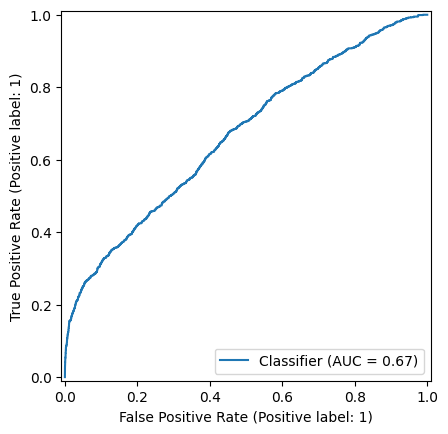

In [11]:
logit_data["prob_1"] = modelo_riesgo_1.predict(logit_data)
logit_data["pred_1"] = (logit_data["prob_1"] >= 0.5).astype(int)

print(classification_report(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
))

RocCurveDisplay.from_predictions(
    logit_data["late_delivery"].astype(int),
    logit_data["prob_1"]
)

plt.show()


El analista escribe en su informe:

> “El modelo tiene un Accuracy alto, por lo tanto permite detectar correctamente los pedidos que se atrasarán y debería pasar a producción.”


1. identifica qué tipo de modelo utilizó y justificar por qué es o no apropiado para la variable objetivo
2. interpreta correctamente el Odd de la variable `days_to_carrier`
3. evalua la calidad predictiva del modelo utilizando la matriz de confusión, métricas de clasificación y/o curva ROC
4. evalua lo que expuso el analista y determina si es correcto para este problema
5. indica si mantendrías un threshold de `0.5` o si probarías otro valor. No es necesario encontrar un threshold “óptimo”, pero debes justificar tu decisión.

### Tu análisis


Matriz de confusión del Modelo de Riesgo 1:
[[13337    25]
 [ 1103    73]]


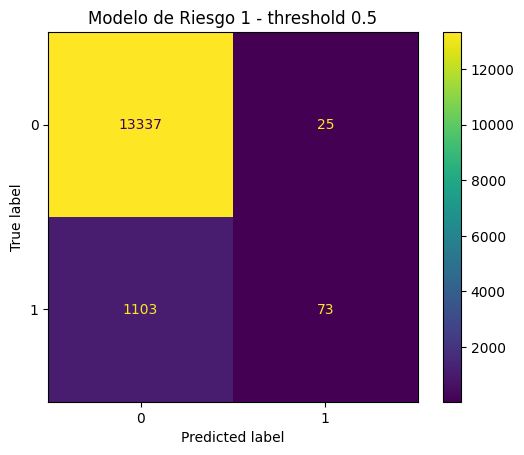

AUC Modelo 1: 0.667

Distribución de la variable objetivo:


,proporción
late_delivery,
0.000,0.919
1.000,0.081


Beta days_to_carrier: 0.1111
Odds Ratio days_to_carrier: 1.1175
Cambio porcentual en los odds: 11.75%


,threshold,accuracy,precision_atraso,recall_atraso,f1_atraso
0,0.050,0.348,0.097,0.850,0.174
1,0.080,0.665,0.126,0.531,0.204
2,0.100,0.780,0.159,0.401,0.228
3,0.150,0.891,0.296,0.252,0.272
4,0.200,0.913,0.413,0.178,0.249
5,0.300,0.922,0.571,0.119,0.197
6,0.400,0.923,0.669,0.086,0.152
7,0.500,0.922,0.745,0.062,0.115


                           Logit Regression Results                           
Dep. Variable:          late_delivery   No. Observations:                10904
Model:                          Logit   Df Residuals:                    10896
Method:                           MLE   Df Model:                            7
Date:                Sun, 30 Aug 2026   Pseudo R-squ.:                0.003055
Time:                        19:49:14   Log-Likelihood:                -3053.9
converged:                       True   LL-Null:                       -3063.3
Covariance Type:            nonrobust   LLR p-value:                  0.009128
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -2.0846      0.229     -9.112      0.000      -2.533      -1.636
C(is_weekend_purchase)[T.1]    -0.0677      0.085     -0.800      0.424      -0.

,threshold,accuracy,precision_atraso,recall_atraso,f1_atraso,TN,FP,FN,TP
0,0.050,0.087,0.081,0.997,0.150,24,3317,1,293
1,0.080,0.497,0.101,0.656,0.174,1615,1726,101,193
2,0.100,0.896,0.111,0.041,0.060,3245,96,282,12
3,0.150,0.918,0.000,0.000,0.000,3337,4,294,0
4,0.200,0.919,0.000,0.000,0.000,3340,1,294,0
5,0.500,0.919,0.000,0.000,0.000,3341,0,294,0


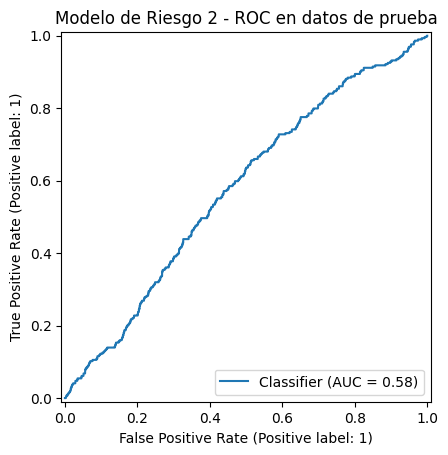

In [12]:
# Matriz de confusión y AUC del modelo entregado por el analista
cm_1 = confusion_matrix(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
)

print("Matriz de confusión del Modelo de Riesgo 1:")
print(cm_1)

ConfusionMatrixDisplay.from_predictions(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
)
plt.title("Modelo de Riesgo 1 - threshold 0.5")
plt.show()

auc_1 = roc_auc_score(
    logit_data["late_delivery"].astype(int),
    logit_data["prob_1"]
)

print(f"AUC Modelo 1: {auc_1:.3f}")
print("\nDistribución de la variable objetivo:")
display(
    logit_data["late_delivery"]
    .value_counts(normalize=True)
    .sort_index()
    .rename("proporción")
    .to_frame()
)

# Odds ratio de days_to_carrier
beta_days = modelo_riesgo_1.params["days_to_carrier"]
odds_days = np.exp(beta_days)

print(f"Beta days_to_carrier: {beta_days:.4f}")
print(f"Odds Ratio days_to_carrier: {odds_days:.4f}")
print(f"Cambio porcentual en los odds: {(odds_days - 1) * 100:.2f}%")

# Cómo cambia el desempeño cuando movemos el threshold
filas_threshold = []

for threshold in [0.05, 0.08, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
    pred = (logit_data["prob_1"] >= threshold).astype(int)

    filas_threshold.append({
        "threshold": threshold,
        "accuracy": accuracy_score(logit_data["late_delivery"], pred),
        "precision_atraso": precision_score(
            logit_data["late_delivery"], pred, zero_division=0
        ),
        "recall_atraso": recall_score(logit_data["late_delivery"], pred),
        "f1_atraso": f1_score(logit_data["late_delivery"], pred)
    })

display(pd.DataFrame(filas_threshold))

# Modelo de Riesgo 2
# Si la predicción se quiere hacer al inicio del procesamiento, days_to_carrier,
# remaining_days y approval_hours todavía no están disponibles.
# Para no perder información física del pedido incorporamos peso y volumen.
riesgo2_data = delivered[
    delivered["late_delivery"].notna()
    & delivered["total_price"].notna()
    & delivered["total_freight"].notna()
    & delivered["n_items"].notna()
    & delivered["n_categories"].notna()
    & delivered["total_weight_g"].notna()
    & delivered["total_volume_cm3"].notna()
].copy()

train_idx, test_idx = train_test_split(
    riesgo2_data.index,
    test_size=0.25,
    random_state=42,
    stratify=riesgo2_data["late_delivery"]
)

riesgo_train = riesgo2_data.loc[train_idx].copy()
riesgo_test = riesgo2_data.loc[test_idx].copy()

modelo_riesgo_2 = smf.logit(
    """
    late_delivery
    ~ total_price
    + total_freight
    + n_items
    + n_categories
    + total_weight_g
    + total_volume_cm3
    + C(is_weekend_purchase)
    """,
    data=riesgo_train
).fit(disp=False)

print(modelo_riesgo_2.summary())

riesgo_test["prob_2"] = modelo_riesgo_2.predict(riesgo_test)
auc_2 = roc_auc_score(riesgo_test["late_delivery"], riesgo_test["prob_2"])
print(f"AUC Modelo de Riesgo 2 en test: {auc_2:.3f}")

# Revisamos algunos thresholds sobre el conjunto de test.
evaluacion_riesgo_2 = []

for threshold in [0.05, 0.08, 0.10, 0.15, 0.20, 0.50]:
    pred = (riesgo_test["prob_2"] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        riesgo_test["late_delivery"].astype(int), pred
    ).ravel()

    evaluacion_riesgo_2.append({
        "threshold": threshold,
        "accuracy": accuracy_score(riesgo_test["late_delivery"], pred),
        "precision_atraso": precision_score(
            riesgo_test["late_delivery"], pred, zero_division=0
        ),
        "recall_atraso": recall_score(riesgo_test["late_delivery"], pred),
        "f1_atraso": f1_score(riesgo_test["late_delivery"], pred),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

display(pd.DataFrame(evaluacion_riesgo_2))

RocCurveDisplay.from_predictions(
    riesgo_test["late_delivery"].astype(int),
    riesgo_test["prob_2"]
)
plt.title("Modelo de Riesgo 2 - ROC en datos de prueba")
plt.show()


**Recomendación al equipo**

**1. Tipo de modelo.**  
El analista usó una **regresión logística binaria**, que sí corresponde al tipo de variable que queremos modelar, porque `late_delivery` toma dos valores: 0 si el pedido llega a tiempo y 1 si se atrasa. El modelo estima una probabilidad y recién después usamos un threshold para convertir esa probabilidad en una clasificación 0/1.

**2. Interpretación de `days_to_carrier`.**  
El coeficiente es aproximadamente 0,111 y su exponencial entrega un odds ratio cercano a **1,118**. Entonces, manteniendo constantes las demás variables, cada día adicional que pasa antes de entregar el pedido al transportista **multiplica los odds de atraso por 1,118**, equivalente a un aumento aproximado de **11,8% en los odds**. No diría que la probabilidad aumenta 11,8 puntos porcentuales, porque odds y probabilidad no son lo mismo.

**3 y 4. Calidad predictiva y evaluación de la conclusión del analista.**  
El Accuracy cercano a 92% suena alto, pero es engañoso si lo miramos solo. Cerca de **91,9% de los pedidos no se atrasa**, por lo que acertar la clase mayoritaria ya permite obtener una exactitud grande. Con threshold 0,5 el modelo identifica solo **73 de 1.176 atrasos**, lo que da un recall de aproximadamente **6,2%** para la clase que realmente nos interesa detectar. El AUC es cercano a **0,667**: existe algo de capacidad de discriminación, pero no es suficientemente fuerte como para justificar por sí sola un paso a producción.

**5. Threshold.**  
Tampoco dejaría 0,5 como una decisión automática. Cuando bajamos el punto de corte aumenta el recall, pero aparecen muchas más falsas alarmas. Por ejemplo, en el Modelo 1 un threshold cercano a 0,15 entrega un equilibrio bastante mejor que 0,5 entre precisión y recall. El valor correcto depende del costo operativo: si es más grave dejar pasar un pedido que se va a atrasar que revisar una alerta falsa, tiene sentido trabajar con un threshold menor.

Hay además un problema que para mí es más importante que el threshold. Si la predicción debe hacerse **al inicio del procesamiento del pedido**, `days_to_carrier`, `remaining_days` y también `approval_hours` todavía dependen de eventos que ocurren después de la compra. Usarlas hace que el modelo tenga información que en producción todavía no existiría. Por eso el Modelo de Riesgo 2 elimina las tres y agrega información física disponible del pedido, como peso y volumen. Además se evalúa con una separación entrenamiento/test para no medir el desempeño sobre los mismos datos usados para estimar el modelo.

El resultado del Modelo 2 es un AUC de aproximadamente **0,575 en test**, muy cercano a una discriminación débil. Con threshold 0,5 prácticamente no identifica atrasos; al bajarlo aumenta el recall, pero el costo es una gran cantidad de falsos positivos. Mi conclusión sería **no pasar todavía ninguno de los dos modelos a producción**. El Modelo 1 muestra mejor AUC, pero parte de esa ventaja proviene de variables que no serían conocidas en el momento planteado. El Modelo 2 respeta mejor ese momento de decisión, pero deja claro que con las variables tempranas disponibles todavía falta señal predictiva. El paso siguiente sería buscar mejores variables logísticas conocidas al inicio —por ejemplo transportista, zona, distancia o temporada— y luego volver a validar el modelo en datos futuros.


---

# Cuarto Bloque (20 puntos)

El equipo de Operaciones necesita anticipar el número de pedidos que recibirá durante los próximos días para planificar su capacidad.

El analista construyó la siguiente serie diaria utilizando los pedidos observados entre enero y julio de 2018


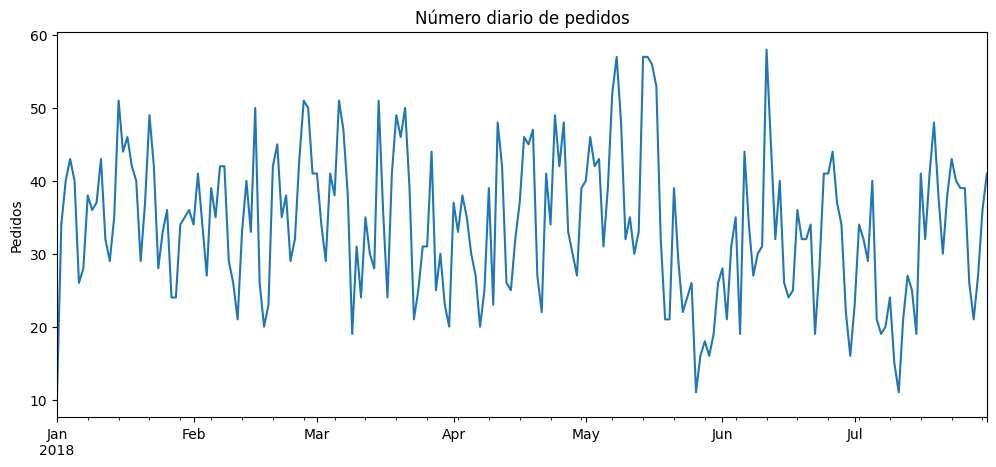

In [13]:
serie_diaria = (
    df
    .dropna(subset=["purchase_date"])
    .groupby("purchase_date")
    .agg(n_orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("purchase_date")
)

serie_diaria = serie_diaria[
    (serie_diaria["purchase_date"] >= "2018-01-01") &
    (serie_diaria["purchase_date"] <= "2018-07-31")
].copy()

serie_diaria.plot(
    x="purchase_date",
    y="n_orders",
    figsize=(12, 5),
    legend=False,
    title="Número diario de pedidos"
)

plt.ylabel("Pedidos")
plt.xlabel("")
plt.show()

In [14]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie = (
    serie_diaria
    .set_index("purchase_date")["n_orders"]
    .asfreq("D")
    .fillna(0)
)

print(serie.head())
print(f"Número de días en la serie: {len(serie)}")

purchase_date
2018-01-01    10
2018-01-02    34
2018-01-03    40
2018-01-04    43
2018-01-05    40
Freq: D, Name: n_orders, dtype: int64
Número de días en la serie: 212


Finalmente considera que "test" es la semana que el equipo está pronosticando

In [15]:
train = serie.iloc[:-7]
test = serie.iloc[-7:]

> El analista sostiene que la cantidad de pedidos de un día depende de lo ocurrido en los últimos 7 anteriores, y que bastaría un ARIMA(7,0,7)


1. Utilice ACF y PACF para evaluar si la elección de un ARIMA(7,0,7) está justificada a priori.

2. Ajuste el modelo y evalúe sus diagnósticos. ¿Encuentra evidencia de problemas importantes en los residuos?

3. Compare el pronóstico con los últimos 7 días reales. Considerando conjuntamente ACF/PACF, diagnósticos y capacidad predictiva, ¿apoyaría el trabajo del analista? Justifique.

### Tu análisis

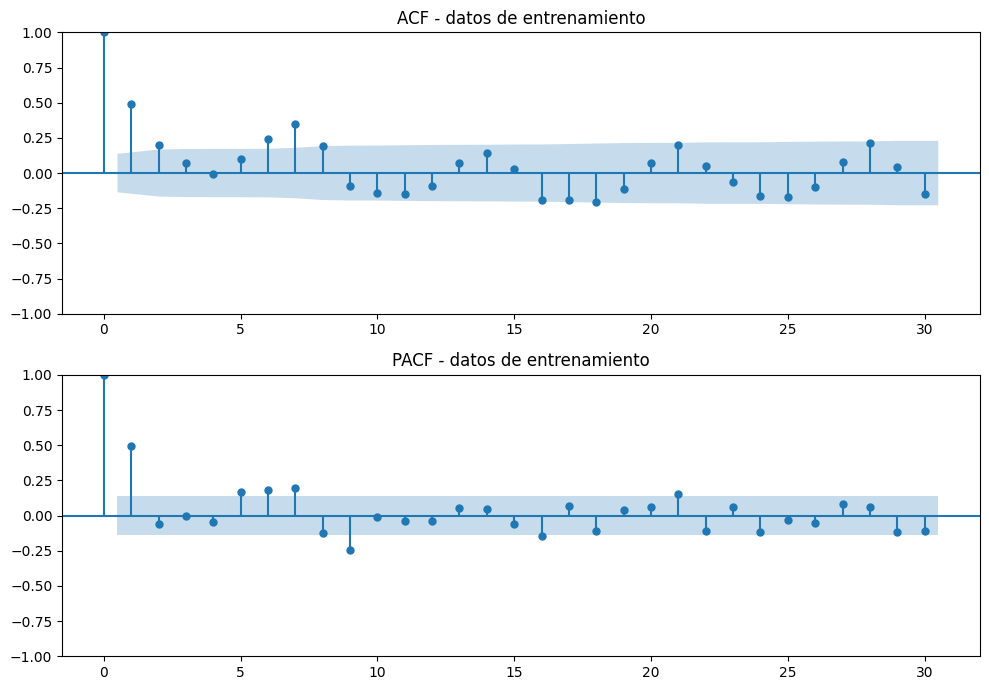

ACF  lags 1-7: [ 0.493  0.198  0.074 -0.007  0.098  0.243  0.349]
PACF lags 1-7: [ 0.493 -0.058 -0.001 -0.045  0.165  0.182  0.194]
ADF estadístico: -4.060
ADF p-value: 0.0011


In [16]:
# 1. ACF/PACF usando solamente train para no mirar la semana reservada como test
from statsmodels.tsa.stattools import acf, pacf

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
plot_acf(train, lags=30, ax=ax[0])
plot_pacf(train, lags=30, ax=ax[1], method="ywm")
ax[0].set_title("ACF - datos de entrenamiento")
ax[1].set_title("PACF - datos de entrenamiento")
plt.tight_layout()
plt.show()

acf_vals = acf(train, nlags=10)
pacf_vals = pacf(train, nlags=10, method="ywm")
print("ACF  lags 1-7:", np.round(acf_vals[1:8], 3))
print("PACF lags 1-7:", np.round(pacf_vals[1:8], 3))

# Como apoyo revisamos si es razonable trabajar con d=0.
adf_stat, adf_p, *_ = adfuller(train)
print(f"ADF estadístico: {adf_stat:.3f}")
print(f"ADF p-value: {adf_p:.4f}")


**1. ¿ACF y PACF justifican un ARIMA(7,0,7)?**

No de forma directa. El hecho de que la serie sea diaria y una semana tenga siete días no significa que automáticamente necesitemos siete términos AR y siete términos MA. La PACF tiene su señal más clara en el lag 1 y también aparece información alrededor del lag 7, lo que hace pensar en una dependencia de corto plazo y en un posible patrón semanal. Eso es distinto a decir que los siete rezagos tengan que entrar por igual al modelo.

Además, la prueba ADF entrega un p-value cercano a **0,0011**, por lo que para este tramo no aparece evidencia de una raíz unitaria. Con esto, usar \(d=0\) es razonable. Mi lectura a priori sería entonces: hay estructura temporal y parece haber una señal semanal, pero ACF/PACF no entregan una justificación limpia para escoger específicamente \((7,0,7)\).


Ajuste inicial
Convergencia: False
Iteraciones: 50
Advertencia: Maximum Likelihood optimization failed to converge. Check mle_retvals



Ajuste con más iteraciones
Convergencia: True
Iteraciones: 211


,ajuste,convergio,iteraciones,logLik,AIC,BIC
0,Inicial,False,50,-700.632,"1,433.263","1,486.431"
1,Con más iteraciones,True,211,-698.257,"1,428.515","1,481.683"


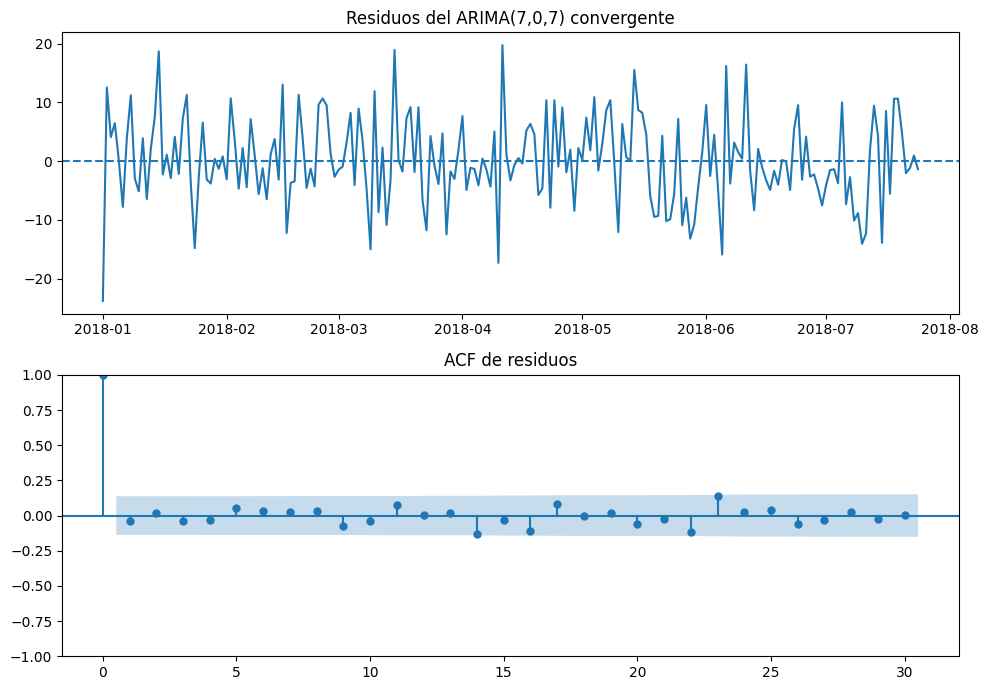

Test de Ljung-Box del ajuste convergente:


,lb_stat,lb_pvalue
7,2.077,0.955
14,9.044,0.828
21,14.512,0.847


In [17]:
# 2. Ajustamos el mismo ARIMA(7,0,7) de dos formas para estudiar la convergencia.
# Primero dejamos la configuración por defecto. Guardamos la advertencia en vez de ocultarla.
with warnings.catch_warnings(record=True) as avisos_iniciales:
    warnings.simplefilter("always")
    modelo_707_inicial = ARIMA(train, order=(7, 0, 7)).fit()

converge_inicial = bool(modelo_707_inicial.mle_retvals.get("converged", False))
iter_inicial = modelo_707_inicial.mle_retvals.get("iterations", np.nan)

print("Ajuste inicial")
print("Convergencia:", converge_inicial)
print("Iteraciones:", iter_inicial)
if avisos_iniciales:
    print("Advertencia:", avisos_iniciales[-1].message)

# Segundo ajuste: damos más iteraciones al optimizador para comprobar si llega a una solución estable.
with warnings.catch_warnings(record=True) as avisos_estables:
    warnings.simplefilter("always")
    modelo_707 = ARIMA(train, order=(7, 0, 7)).fit(
        method_kwargs={"maxiter": 500}
    )

converge_estable = bool(modelo_707.mle_retvals.get("converged", False))
iter_estable = modelo_707.mle_retvals.get("iterations", np.nan)

print("\nAjuste con más iteraciones")
print("Convergencia:", converge_estable)
print("Iteraciones:", iter_estable)
if avisos_estables:
    print("Advertencia:", avisos_estables[-1].message)

comparacion_ajustes = pd.DataFrame({
    "ajuste": ["Inicial", "Con más iteraciones"],
    "convergio": [converge_inicial, converge_estable],
    "iteraciones": [iter_inicial, iter_estable],
    "logLik": [modelo_707_inicial.llf, modelo_707.llf],
    "AIC": [modelo_707_inicial.aic, modelo_707.aic],
    "BIC": [modelo_707_inicial.bic, modelo_707.bic]
})
display(comparacion_ajustes)

# Diagnóstico de residuos del ajuste convergente.
residuos_707 = modelo_707.resid.dropna()

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(residuos_707)
ax[0].axhline(0, linestyle="--")
ax[0].set_title("Residuos del ARIMA(7,0,7) convergente")
plot_acf(residuos_707, lags=30, ax=ax[1])
ax[1].set_title("ACF de residuos")
plt.tight_layout()
plt.show()

ljung_box = acorr_ljungbox(
    residuos_707,
    lags=[7, 14, 21],
    return_df=True
)
print("Test de Ljung-Box del ajuste convergente:")
display(ljung_box)


**2. Diagnóstico y el problema de la convergencia**

Acá aparece un punto interesante. Con la configuración inicial, el optimizador se detiene sin declarar convergencia. Eso significa que el software alcanzó un conjunto de coeficientes, pero **no pudo asegurar que llegó a una solución estable del problema de máxima verosimilitud**. Como el ARIMA(7,0,7) tiene muchos parámetros para una serie de solo 205 días de entrenamiento, no es raro que la optimización sea difícil.

Al permitir más iteraciones, el mismo modelo sí converge. Además, este ajuste tiene una log-verosimilitud mayor y un AIC menor, lo que muestra que el optimizador efectivamente encontró una solución distinta y mejor desde el criterio con el que fue estimado. En los residuos del modelo convergente, Ljung-Box entrega p-values mayores que 0,05 en los lags 7, 14 y 21, por lo que no vemos autocorrelación residual importante. Es decir, temporalmente los residuos se comportan de forma razonable como ruido blanco.

Que el primer ajuste deje residuos aparentemente aceptables no elimina el problema de convergencia. Si el optimizador no terminó correctamente, sus parámetros pueden depender del punto exacto donde se detuvo y pueden cambiar al modificar la versión del software, los valores iniciales o el número de iteraciones. Por eso no trataría ese resultado como un modelo estable solo porque produzca un buen pronóstico en una semana.


In [18]:
# 3. Pronóstico de los últimos 7 días y comparación con referencias simples.
forecast_inicial = modelo_707_inicial.forecast(steps=7)
forecast_estable = modelo_707.forecast(steps=7)

# Baseline 1: promedio histórico del train.
pred_promedio = pd.Series(
    [train.mean()] * 7,
    index=test.index
)

# Baseline 2: repetir los mismos días de la semana anterior.
pred_semana_pasada = pd.Series(
    train.iloc[-7:].values,
    index=test.index
)

comparacion_pronostico = pd.DataFrame({
    "real": test,
    "ARIMA_inicial_no_convergente": forecast_inicial,
    "ARIMA_convergente": forecast_estable,
    "baseline_promedio": pred_promedio,
    "baseline_semana_pasada": pred_semana_pasada
})
display(comparacion_pronostico.round(2))

metricas = []
for nombre, pred, convergio in [
    ("ARIMA inicial", forecast_inicial, converge_inicial),
    ("ARIMA convergente", forecast_estable, converge_estable),
    ("Baseline promedio", pred_promedio, True),
    ("Baseline semana pasada", pred_semana_pasada, True)
]:
    metricas.append({
        "Modelo": nombre,
        "Convergió": convergio,
        "MAE": mean_absolute_error(test, pred),
        "RMSE": root_mean_squared_error(test, pred)
    })

metricas_pronostico = pd.DataFrame(metricas)
display(metricas_pronostico)


,real,ARIMA_inicial_no_convergente,ARIMA_convergente,baseline_promedio,baseline_semana_pasada
2018-07-25,39,36.150,35.180,34.000,41
2018-07-26,39,38.530,36.510,34.000,48
2018-07-27,26,28.660,28.170,34.000,38
2018-07-28,21,28.030,26.820,34.000,30
2018-07-29,27,34.610,35.700,34.000,38
2018-07-30,36,40.310,40.250,34.000,43
2018-07-31,41,38.480,38.870,34.000,40


,Modelo,Convergió,MAE,RMSE
0,ARIMA inicial,False,3.922,4.593
1,ARIMA convergente,True,4.197,4.745
2,Baseline promedio,True,6.715,7.415
3,Baseline semana pasada,True,7.286,8.289


**3. Pronóstico y decisión final**

Lo llamativo es que el ajuste que **no converge puede obtener un MAE algo menor** en estos siete días de test que la versión del mismo ARIMA que sí converge. No ignoraría ese resultado, porque muestra que la estructura \((7,0,7)\) está captando información útil. Sin embargo, tampoco elegiría el modelo no convergente solo porque ganó por unas décimas de MAE en una semana.

La razón es que estamos comparando sobre apenas **7 observaciones**. Una diferencia pequeña de error puede cambiar fácilmente si movemos la semana de prueba. Además, el modelo no convergente no corresponde a una estimación estable: el algoritmo se detuvo antes de completar correctamente la optimización. En cambio, la versión convergente llega a una solución definida, tiene mejor log-verosimilitud/AIC en entrenamiento y deja residuos sin autocorrelación evidente. El menor error puntual del ajuste no convergente es entonces un dato interesante, pero no una razón suficiente para convertirlo en la solución final.

También agregué dos referencias simples. Tanto el promedio histórico como repetir la semana anterior tienen un error mayor que el ARIMA convergente en esta ventana, así que el modelo sí aporta capacidad predictiva. Mi conclusión sería **no apoyar la forma en que el analista escogió el ARIMA(7,0,7), pero tampoco descartarlo**. Una vez bien ajustado, converge y predice esta semana mejor que los baselines. Antes de usarlo en operación compararía modelos más parsimoniosos y una formulación con estacionalidad semanal, y repetiría la validación en varias ventanas temporales. Ahí recién podríamos saber si la ventaja predictiva es estable y no una coincidencia de estos últimos siete días.
